# Phân tích Các Yếu tố Tài chính ảnh hưởng đến Rating Phim

Notebook này thực hiện phân tích mối tương quan giữa **Ngân sách (Budget)**, **Doanh thu (Revenue)** và **Đánh giá trung bình (Rating)** của phim.

## Dữ liệu sử dụng:
1. MovieLens (movies.dat, ratings.dat)
2. TMDB (tmdb_5000_movies.csv)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
%matplotlib inline
sns.set_style('whitegrid')


## 1. Tải và Xử lý Dữ liệu


In [10]:
ratings_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=ratings_cols, engine='python', encoding='latin-1')

movie_ratings = ratings.groupby('MovieID').agg({'Rating':['mean','count']})
movie_ratings.columns = ['avg_rating','vote_count']
movie_ratings.reset_index(inplace=True)
movie_ratings.head()


,MovieID,avg_rating,vote_count
0,1,4.146846,2077
1,2,3.201141,701
2,3,3.016736,478
3,4,2.729412,170
4,5,3.006757,296


In [11]:
movies_cols = ['MovieID','Title','Genres']
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=movies_cols, engine='python', encoding='latin-1')

def clean_title(title):
    return re.sub(r'\s\(\d{4}\)', '', title).strip().lower()

movies['clean_title'] = movies['Title'].apply(clean_title)
movies.head()


,MovieID,Title,Genres,clean_title
0,1,Toy Story (1995),Animation|Children's|Comedy,toy story
1,2,Jumanji (1995),Adventure|Children's|Fantasy,jumanji
2,3,Grumpier Old Men (1995),Comedy|Romance,grumpier old men
3,4,Waiting to Exhale (1995),Comedy|Drama,waiting to exhale
4,5,Father of the Bride Part II (1995),Comedy,father of the bride part ii


In [12]:
tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
tmdb_movies['clean_title'] = tmdb_movies['title'].astype(str).str.lower()
tmdb_movies.head()


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,clean_title
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,avatar
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,pirates of the caribbean: at world's end
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,spectre
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,the dark knight rises
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,john carter


## 2. Ghép nối và Làm sạch Dữ liệu


In [13]:
df_movielens = pd.merge(movies, movie_ratings, on='MovieID', how='inner')
df_financial = pd.merge(df_movielens, tmdb_movies[['clean_title','budget','revenue']], on='clean_title', how='inner')

df_clean = df_financial[(df_financial['budget']>10000) & (df_financial['revenue']>10000) & (df_financial['vote_count']>50)]

df_clean[['Title','budget','revenue','avg_rating']].head()


,Title,budget,revenue,avg_rating
0,Toy Story (1995),30000000,373554033,4.146846
1,GoldenEye (1995),58000000,352194034,3.540541
2,Nixon (1995),44000000,13681765,3.542484
3,Cutthroat Island (1995),98000000,10017322,2.458904
4,Casino (1995),52000000,116112375,3.793255


## 3. Phân tích Tương quan


In [14]:
corr_budget = df_clean['budget'].corr(df_clean['avg_rating'])
corr_revenue = df_clean['revenue'].corr(df_clean['avg_rating'])

corr_budget, corr_revenue


(-0.18365098766299195, 0.12446841012764741)

## 4. Trực quan hóa


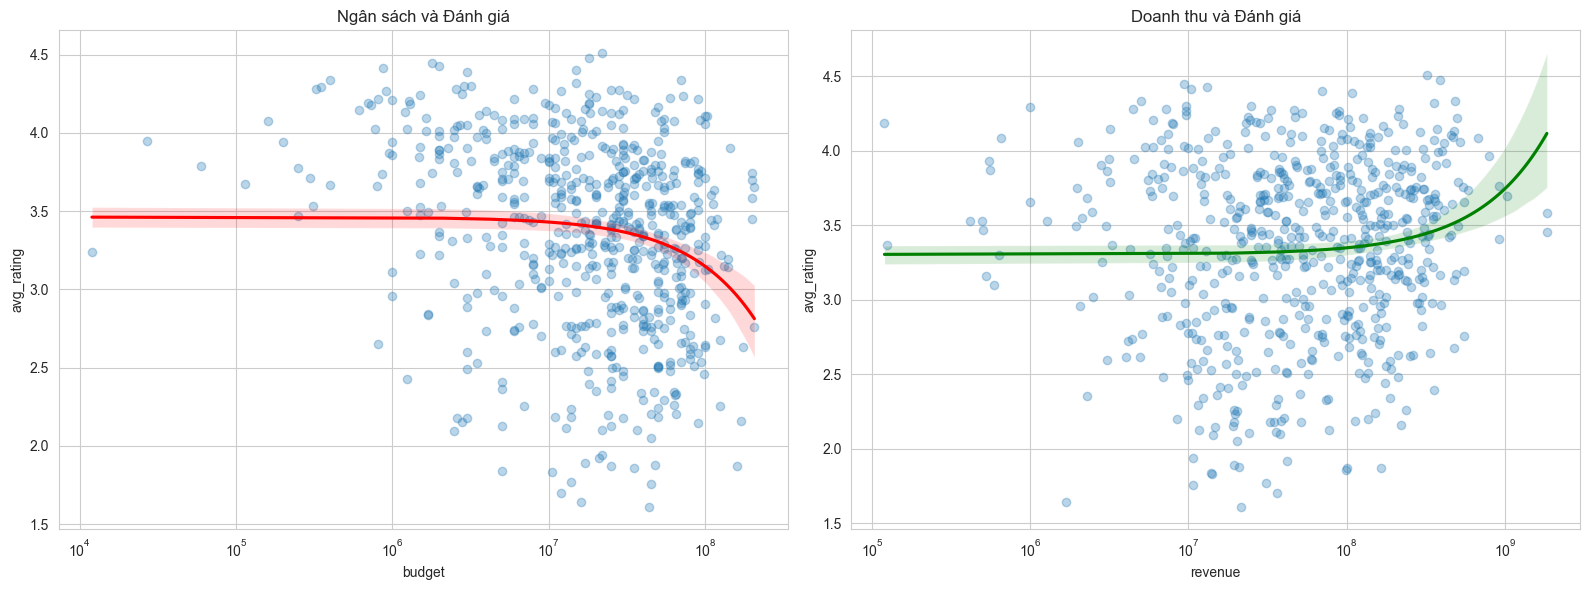

In [16]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_clean, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_clean, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.show()


Kết quả Phân tích: Mối quan hệ giữa Tài chính và Rating
Sau khi tổng hợp dữ liệu từ hai nguồn (MovieLens và TMDB) và loại bỏ các dữ liệu nhiễu, bức tranh về mối quan hệ giữa "Tiền" và "Chất lượng" (thể hiện qua Rating) đã trở nên rõ ràng với những kết quả khá bất ngờ.

1. Về Ngân sách (Budget): Mối liên hệ Tiêu cực (-0.18) Dữ liệu cho thấy một thực tế trái ngược với suy nghĩ thông thường: Tiền không mua được điểm đánh giá cao. Cụ thể, hệ số tương quan giữa ngân sách và điểm rating là -0.18 (tương quan âm).

-> Điều này có nghĩa là việc một bộ phim được đầu tư "khủng" hàng trăm triệu USD cho kỹ xảo và bối cảnh không đảm bảo nó sẽ nhận được điểm cao từ cộng đồng khán giả. Thậm chí, xu hướng chung cho thấy khi ngân sách tăng lên quá cao (bom tấn), điểm đánh giá trung bình lại có xu hướng giảm nhẹ.

Lý do: Các bộ phim kinh phí lớn thường tập trung vào tính giải trí đại chúng, trong khi cộng đồng người dùng (đặc biệt là trên MovieLens) thường khắt khe hơn và ưu ái các tác phẩm có chiều sâu nội dung, kịch bản hay – những yếu tố thường thấy ở các phim tâm lý hoặc độc lập có kinh phí thấp hơn.

2. Về Doanh thu (Revenue): Mối liên hệ Tích cực (+0.12) Ngược lại với ngân sách, khi xét đến doanh thu, chúng ta thấy một tín hiệu tích cực hơn với hệ số tương quan là +0.12 (tương quan dương).

-> Mặc dù con số này không quá lớn, nhưng nó khẳng định rằng chất lượng phim có đi đôi với thành công thương mại. Những bộ phim được đánh giá cao (Rating tốt) thường có sức lan tỏa mạnh mẽ (hiệu ứng truyền miệng), từ đó thúc đẩy doanh thu phòng vé tăng lên.

Kết luận: Một bộ phim hay có xu hướng kiếm được nhiều tiền hơn, nhưng một bộ phim kiếm được nhiều tiền (do marketing, thương hiệu) chưa chắc đã là một bộ phim hay.
